# 01 - Data Understanding, Validation and EDA

**Problem.** Retalix refreshes its catalogue range every six months. For every product listed in an edition we predict whether it will be discontinued at the refresh (`DiscontinuedTF`).

This notebook validates the raw data, checks the assumptions behind the prediction design and investigates leakage risks. All reusable logic lives in `src/product_discontinuation/data.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from product_discontinuation import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

In [2]:
from product_discontinuation import data

catalogue = data.load_catalogue()
products = data.load_product_details()
dictionary = pd.read_excel(config.DATA_DICTIONARY_PATH)
print(catalogue.shape, products.shape)
dictionary[["Dataset", "Field Name", "Data Type", "Description"]]

(3625659, 9) (77372, 6)


,Dataset,Field Name,Data Type,Description
0,ProductDetails,ProductKey,Integer (classifier),Unique product identifier
1,ProductDetails,Supplier,Integer (classifier),Supplier identifier. A supplier is typically a...
2,ProductDetails,HierarchyLevel1,Integer (classifier),Product hierarchy by type of products. Example...
3,ProductDetails,HierarchyLevel2,Integer (classifier),HierarchyLevel1 maps many-to-one to HierarchyL...
4,ProductDetails,DIorDOM,Text (classifier),Indicates whether a product is sourced domesti...
5,ProductDetails,Seasonal,Boolean,"1 for products that have a distinct ""on"" seaso..."
6,CatalogueDiscontinuation,CatEdition,Integer (ordinal),"There is a range refresh every 6 months, still..."
7,CatalogueDiscontinuation,SpringSummer,Boolean,"Each range is either a spring/summer range, la..."
8,CatalogueDiscontinuation,ProductKey,Integer (classifier),Unique product identifier
9,CatalogueDiscontinuation,WeeksOut,Integer (ordinal),Number of weeks before the date of potential d...


## 1. Schema and integrity validation
`validate_catalogue` raises on hard errors (missing columns, nulls, duplicate weekly keys, invalid `Status`, `WeeksOut` outside [-24, -1], negative measures, inconsistent target within a product-edition) and returns soft data-quality findings.

In [3]:
report = data.validate_catalogue(catalogue)
data.validate_product_details(products)
report

{'rows': 3625659,
 'products': 70227,
 'product_editions': 178905,
 'editions': [88, 89, 90, 91, 92, 93, 94],
 'zero_price_rows': 12880,
 'zero_actuals_rows': 131608,
 'groups_with_week_gaps': 7442,
 'inconsistent_target_groups': 0}

In [4]:
print("dtypes:\n", catalogue.dtypes)
print("\nMissing values:", catalogue.isna().sum().sum(), "| ProductDetails missing:", products.isna().sum().sum())
print("Fully duplicated rows:", catalogue.duplicated().sum())
print("Duplicate (CatEdition, ProductKey, WeeksOut):", catalogue.duplicated(["CatEdition", "ProductKey", "WeeksOut"]).sum())
print("Duplicate ProductKey in ProductDetails:", products["ProductKey"].duplicated().sum())

dtypes:
 CatEdition           int64
SpringSummer          bool
ProductKey           int64
WeeksOut             int64
Status              object
SalePriceIncVAT    float64
ForecastPerWeek    float64
ActualsPerWeek     float64
DiscontinuedTF        bool
dtype: object

Missing values: 0 | ProductDetails missing: 0
Fully duplicated rows: 0
Duplicate (CatEdition, ProductKey, WeeksOut): 0
Duplicate ProductKey in ProductDetails: 0


### Join cardinality: ProductDetails must be many-to-one with no unmatched products

In [5]:
merged = data.merge_product_details(catalogue, products)
print("rows before/after join:", len(catalogue), len(merged))
print("catalogue products without details:", len(set(catalogue.ProductKey) - set(products.ProductKey)))
print("products in details never in catalogue:", len(set(products.ProductKey) - set(catalogue.ProductKey)))

rows before/after join: 3625659 3625659
catalogue products without details: 0
products in details never in catalogue: 7145


## 2. Catalogue editions and the censored edition
Edition 94 is labelled 100% discontinued and stops at `WeeksOut = -13`. A real outcome cannot be 100% discontinued with 71% of its products carried over from edition 93; the label is a placeholder for an outcome that is not yet known. **Edition 94 is excluded from training and evaluation and treated as the live, unlabelled edition** - scored 13 weeks before its refresh, which also motivates the primary horizon of 13 weeks.

In [6]:
editions = catalogue.groupby("CatEdition").agg(
    spring_summer=("SpringSummer", "first"), rows=("ProductKey", "size"),
    products=("ProductKey", "nunique"), discontinued_row_rate=("DiscontinuedTF", "mean"),
    first_week=("WeeksOut", "min"), last_week=("WeeksOut", "max"))
print("Incomplete editions detected:", data.find_incomplete_editions(catalogue))
editions

Incomplete editions detected: [94]


,spring_summer,rows,products,discontinued_row_rate,first_week,last_week
CatEdition,,,,,,
88,False,541816,25255,0.358745,-24,-1
89,True,553854,24946,0.347453,-24,-1
90,False,514454,23533,0.368698,-24,-1
91,True,536707,23873,0.299398,-24,-1
92,False,526155,23508,0.301654,-24,-1
93,True,621276,28097,0.341554,-24,-1
94,False,331397,29693,1.000000,-24,-13


In [7]:
labelled, live = data.split_labelled(catalogue)
groups = labelled.groupby(config.GROUP_KEYS)["DiscontinuedTF"].first()
print(f"Row-level positive rate (all editions):      {catalogue.DiscontinuedTF.mean():.3f}")
print(f"Group-level positive rate (all editions):    {catalogue.groupby(config.GROUP_KEYS).DiscontinuedTF.first().mean():.3f}")
print(f"Group-level positive rate (labelled 88-93):  {groups.mean():.3f}  (n = {len(groups)})")

Row-level positive rate (all editions):      0.397
Group-level positive rate (all editions):    0.468
Group-level positive rate (labelled 88-93):  0.363  (n = 149212)


## 3. Prediction unit
The target is constant within every (CatEdition, ProductKey) group, and one decision is made per product per refresh. Treating weekly rows as independent samples would (a) duplicate each label up to 24 times, (b) weight products by how long they were observed and (c) let rows of the same product appear in train and test. **The prediction unit is a product within a catalogue edition**, observed at a fixed number of weeks before the refresh.

In [8]:
print("Groups with inconsistent target:", data.check_target_consistency(catalogue))
cover = labelled.groupby(config.GROUP_KEYS)["WeeksOut"].agg(["min", "max", "size"])
cover["gap"] = (cover["max"] - cover["min"] + 1) != cover["size"]
cover = cover.join(groups)
print("Groups with gaps in weekly coverage:", cover.gap.sum())
print(cover.groupby(cover["max"] == -1)["DiscontinuedTF"].agg(["mean", "size"]).rename(index={True: "observed to week -1", False: "disappears early"}))

Groups with inconsistent target: 0
Groups with gaps in weekly coverage: 5885
                         mean    size
max                                  
disappears early     0.909360   11165
observed to week -1  0.318507  138047


**Leakage risk - disappearing products.** Products whose records stop before week -1 are 91% discontinued. Any feature using the number of weekly observations or the last observed week across the *whole* edition would leak the outcome. Features are therefore computed only from rows up to the prediction week.

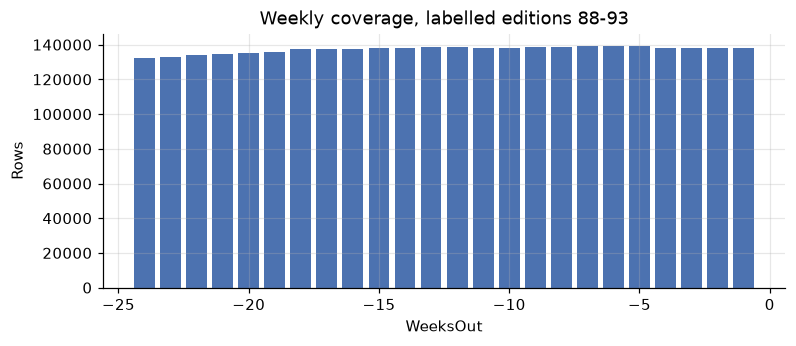

In [9]:
weeks = labelled.groupby("WeeksOut").size()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(weeks.index, weeks.values, color="#4C72B0")
ax.set(xlabel="WeeksOut", ylabel="Rows", title="Weekly coverage, labelled editions 88-93")
plt.show()

Every week from -24 to -1 is covered for all labelled editions, so horizons of 24, 13, 6 and 1 weeks are all supported. (The step at -12 comes from edition 94 in the full table; here it reflects products entering/leaving.)

## 4. Numerical distributions and outliers

In [10]:
measures = ["SalePriceIncVAT", "ForecastPerWeek", "ActualsPerWeek"]
catalogue[measures].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]).round(2)

,SalePriceIncVAT,ForecastPerWeek,ActualsPerWeek
0.000,0.00,0.00,0.00
0.010,3.99,0.47,0.00
0.250,15.99,15.14,10.56
0.500,29.99,46.60,38.67
0.750,69.99,127.06,110.83
0.990,799.00,1291.96,1052.36
0.999,1525.39,4025.76,3017.07
1.000,5000.00,163757.50,43626.33


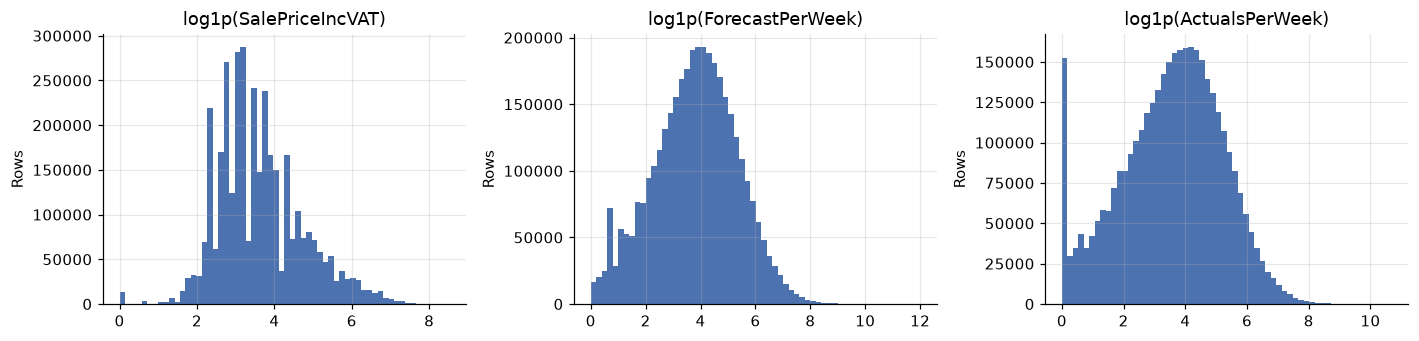

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, measures):
    ax.hist(np.log1p(catalogue[col]), bins=60, color="#4C72B0")
    ax.set(title=f"log1p({col})", ylabel="Rows")
plt.tight_layout(); plt.show()

In [12]:
zero_price = labelled.groupby(config.GROUP_KEYS)["SalePriceIncVAT"].agg(lambda s: (s == 0).mean())
print("Groups with price 0 in every week:", (zero_price == 1).sum(), "| partially zero:", ((zero_price > 0) & (zero_price < 1)).sum())
print("Rows with zero actuals:", (catalogue.ActualsPerWeek == 0).sum())
catalogue.nlargest(5, "ForecastPerWeek")

Groups with price 0 in every week: 682 | partially zero: 1
Rows with zero actuals: 131608


,CatEdition,SpringSummer,ProductKey,WeeksOut,Status,SalePriceIncVAT,ForecastPerWeek,ActualsPerWeek,DiscontinuedTF
1703962,93,True,35912,-2,RO,25.00,163757.500,132.478,True
1284572,91,True,68005,-2,RI,1.25,150000.500,0.000,True
1703290,93,True,59199,-2,RO,10.00,120000.000,178.739,True
1284571,91,True,68005,-3,RI,1.25,100000.333,0.000,True
2235557,90,False,44221,-5,RI,14.99,82906.000,4235.450,False


**Outlier decisions**
- *Price = 0*: occurs for entire product-editions; it is not a plausible retail price, so it is treated as **missing** (imputed, with a `price_missing` flag) rather than removed.
- *Zero actuals*: legitimate (new or slow-moving products) - kept, with a `zero_actuals` flag.
- *Extreme forecasts/actuals* (e.g. 163,757 units/week): rare, heavy right tail typical of retail demand (promotions, bulk orders). Not removed; all demand measures are `log1p`-transformed so they do not dominate the linear model, and tree models are insensitive to monotone scale.
- Prices barely change within an edition, so price-change features would carry no signal.

In [13]:
first, last = (labelled.sort_values("WeeksOut").groupby(config.GROUP_KEYS)["SalePriceIncVAT"].agg(f) for f in ("first", "last"))
print("Product-editions with >5% price drop during the edition:", ((last < first * 0.95) & (first > 0)).sum())

Product-editions with >5% price drop during the edition: 52


## 5. Demand vs outcome (at 13 weeks before refresh)

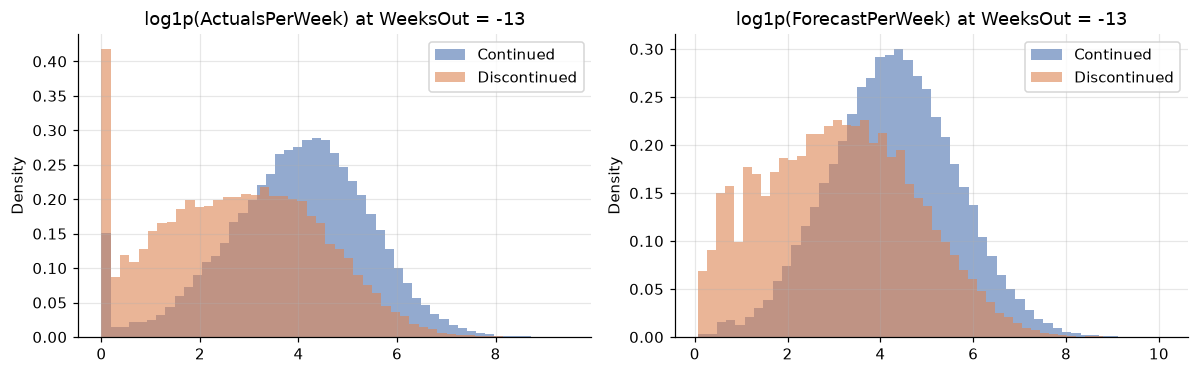

In [14]:
snap = labelled[labelled.WeeksOut == -13]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["ActualsPerWeek", "ForecastPerWeek"]):
    for label, colour in [(False, "#4C72B0"), (True, "#DD8452")]:
        ax.hist(np.log1p(snap.loc[snap.DiscontinuedTF == label, col]), bins=50, alpha=0.6, density=True,
                color=colour, label="Discontinued" if label else "Continued")
    ax.set(title=f"log1p({col}) at WeeksOut = -13", ylabel="Density"); ax.legend()
plt.tight_layout(); plt.show()

## 6. `Status` - leakage investigation
The data dictionary defines `Status` as *"effectively a prediction of DiscontinuedTF"*: RI if the product is listed for inclusion after the refresh, RO if it is not (or not yet) listed. It is recorded weekly, so it is technically known at the prediction week, but it **is the planners' own decision about the outcome**. Close to the refresh it is nearly the label itself.

In [15]:
pd.crosstab(labelled.Status, labelled.DiscontinuedTF, normalize="index").round(3)

DiscontinuedTF,False,True
Status,,
RI,0.911,0.089
RO,0.205,0.795


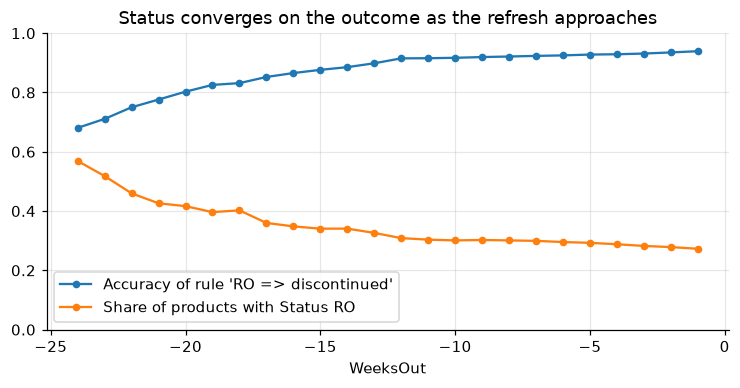

,accuracy,RO share
WeeksOut,,
-24,0.681,0.569
-13,0.898,0.326
-6,0.925,0.295
-1,0.939,0.273


In [16]:
by_week = labelled.assign(pred=labelled.Status.eq("RO")).groupby("WeeksOut").apply(
    lambda t: pd.Series({"accuracy": (t.pred == t.DiscontinuedTF).mean(), "RO share": t.pred.mean()}), include_groups=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(by_week.index, by_week["accuracy"], marker="o", ms=4, label="Accuracy of rule 'RO => discontinued'")
ax.plot(by_week.index, by_week["RO share"], marker="o", ms=4, label="Share of products with Status RO")
ax.set(xlabel="WeeksOut", ylim=(0, 1), title="Status converges on the outcome as the refresh approaches"); ax.legend()
plt.show()
by_week.loc[[-24, -13, -6, -1]].round(3)

**Decision.** The primary model **excludes `Status`**. Its purpose is an independent, data-driven early warning that supports the range-planning decision; a model that takes the decision as an input mostly reproduces it and would be circular in deployment. `Status` is used only as (a) a rule-based benchmark and (b) a clearly labelled "with Status" comparison model.

## 7. Products across editions and changing range mix

In [17]:
per_product = labelled.groupby("ProductKey")["CatEdition"].nunique()
print("Editions per product:", per_product.value_counts().sort_index().to_dict())
keys = set(zip(groups.index.get_level_values(0), groups.index.get_level_values(1)))
nxt = pd.Series([(e + 1, p) in keys for e, p in groups.index], index=groups.index)
print(nxt[groups.index.get_level_values(0) < 93].groupby(groups[groups.index.get_level_values(0) < 93]).mean().rename("P(listed in next edition)"))

Editions per product: {1: 24484, 2: 14351, 3: 10258, 4: 4316, 5: 3102, 6: 5413}
DiscontinuedTF
False    0.999586
True     0.208626
Name: P(listed in next edition), dtype: float64


Products recur across editions, so a random split would put the same product in train and test. Validation is **chronological by edition**; ProductKey is never used as a feature. 21% of products labelled discontinued reappear in the next edition, so the previous edition's outcome is a useful (legitimately past) feature.

In [18]:
mix = merged[merged.WeeksOut == -13].groupby("CatEdition")["HierarchyLevel2"].nunique()
print("Distinct HierarchyLevel2 categories per edition:", mix.to_dict())

Distinct HierarchyLevel2 categories per edition: {88: 28, 89: 27, 90: 26, 91: 17, 92: 17, 93: 17, 94: 7}


The range narrows over time (28 top-level categories in edition 88, 7 in live edition 94). This is genuine distribution shift that the monitoring module must detect.

## Summary of findings
| Finding | Consequence |
|---|---|
| No missing values, no duplicates, 1:1 product join | No imputation needed for raw fields; join validated |
| Target constant per product-edition | Prediction unit = product-edition |
| Edition 94 censored (100% True, ends at -13) | Excluded from training/evaluation; used as live scoring set |
| Labelled group-level positive rate = 36.3% | Moderate imbalance - use PR-AUC, F1, balanced accuracy |
| Products disappearing early are 91% discontinued | Only rows up to the prediction week are used |
| Status is the planners' decision | Excluded from primary model; benchmark only |
| Price 0 for whole groups | Treated as missing |
| Heavy-tailed demand | log1p transforms, no removal |
| Products recur across editions; range mix shifts | Edition-based chronological validation; drift monitoring |